<a href="https://colab.research.google.com/github/hanin1106/2024-02-database/blob/main/%EC%84%A0%ED%98%95%EB%8C%80%EC%88%98%ED%95%99_TIE_%EC%B0%90.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [388]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [389]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [390]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

In [391]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

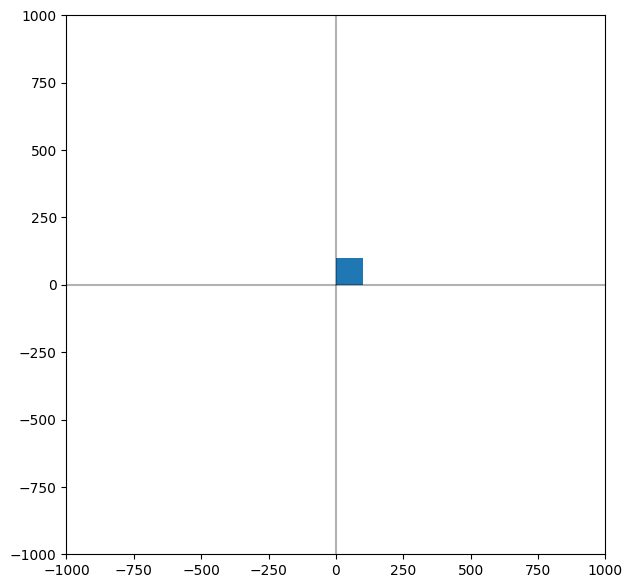

In [392]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* ...

In [393]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([
      [1.0, 0.0, dx],
      [0.0, 1.0, dy],
      [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [394]:
#크기 변환 함수
def scale(p, sx, sy):
  hp = np.array((p[0], p[1], 1.0))
  m = np.array([
      [sx, 0, 0],
      [0, sy, 0],
      [0, 0, 1.0]])

  q = np.dot(m,hp)
  q = np.array([q[0], q[1]])
  return q

In [395]:
#회전 변환 함수
def rotate(p, theta):
  hp = np.array([p[0], p[1], 1.0])

  angle_rad = theta

  m = np.array([
      [np.cos(angle_rad), -np.sin(angle_rad), 0],
      [np.sin(angle_rad),  np.cos(angle_rad), 0],
      [ 0, 0, 1.0]])

  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q

In [396]:
#x축 반전 함수
def reflect_x(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([
      [1.0, 0, 0],
      [0, -1.0, 0 ],
      [0, 0, 1.0]])

  q = np.dot(m,hp)
  q = np.array([q[0], q[1]])
  return q

In [397]:
#y축 반전 함수
def reflect_y(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([
      [-1.0, 0, 0],
      [0, 1.0, 0 ],
      [0, 0, 1.0]])

  q = np.dot(m,hp)
  q = np.array([q[0], q[1]])
  return q


In [398]:
#x축 기울기 변환
def shear_x(p, sx):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([
      [1.0, sx, 0],
      [0, 1.0, 0 ],
      [0, 0, 1.0]])

  q = np.dot(m,hp)
  q = np.array([q[0], q[1]])
  return q

In [399]:
#y축 기울기 변환
def shear_y(p, sy):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([
      [1.0, 0, 0],
      [sy, 1.0, 0 ],
      [0, 0, 1.0]])

  q = np.dot(m,hp)
  q = np.array([q[0], q[1]])
  return q

#### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

In [400]:
def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(5, 5)
  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)


  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [401]:
def draw_left_wing(ax, p1, p2, p3, p4): #왼쪽 날개
  # 1. 원래 사각형을 원점으로 이동
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환
  q1 = scale(q1, 1, 8)
  q2 = scale(q2, 1, 8)
  q3 = scale(q3, 1, 8)
  q4 = scale(q4, 1, 8)


  #3. 세로 높이 조정
  q1[1] = q1[1] * 1.4
  q4[1] = q4[1] * 1.4
  q2[1] = q2[1] * 0.6
  q3[1] = q3[1] * 0.6

  # 4. 이동 변환
  q1 = translate(q1, -800, 0)
  q2 = translate(q2, -800, 0)
  q3 = translate(q3, -800, 0)
  q4 = translate(q4, -800, 0)

  # 5. 다각형 그리기
  draw_rectangle(ax, q1, q2, q3, q4)



In [402]:
def draw_right_wing(ax, p1, p2, p3, p4): #오른쪽 날개
  #1.사각형을 원점으로 이동
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  #2.크기 변화
  q1 = scale(q1, 1, 8)
  q2 = scale(q2, 1, 8)
  q3 = scale(q3, 1, 8)
  q4 = scale(q4, 1, 8)

  #3.세로 높이 조정 (왼쪽 세로는 늘리고, 오른쪽 세로는 줄임)
  q1[1] = q1[1] * 1.4
  q4[1] = q4[1] * 1.4
  q2[1] = q2[1] * 0.7
  q3[1] = q3[1] * 0.7

  # 4.이동 변환
  q1 = translate(q1, -800, 0)
  q2 = translate(q2, -800, 0)
  q3 = translate(q3, -800, 0)
  q4 = translate(q4, -800, 0)

  # 5.y축 반전
  q1 = reflect_y(q1)
  q2 = reflect_y(q2)
  q3 = reflect_y(q3)
  q4 = reflect_y(q4)


  # 6.다각형 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [403]:
def draw_left_top_arm(ax, p1, p2, p3, p4):  # 왼쪽 위 날개축
  # 1. 사각형을 원점으로 이동
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. x축 기울기 변환 적용
  q1 = shear_x(q1, -1)
  q2 = shear_x(q2, -1)
  q3 = shear_x(q3, -1)
  q4 = shear_x(q4, -1)

  # 3. 크기 변화
  q1 = scale(q1, 1, 7)
  q2 = scale(q2, 1, 7)
  q3 = scale(q3, 1, 7)
  q4 = scale(q4, 1, 7)

  # 4. 회전 변환
  q1 = rotate(q1, -3.14/2.1)
  q2 = rotate(q2, -3.14/2.1)
  q3 = rotate(q3, -3.14/2.1)
  q4 = rotate(q4, -3.14/2.1)

  # 5. 이동 변환
  q1 = translate(q1, -500, 60)
  q2 = translate(q2, -500, 60)
  q3 = translate(q3, -500, 60)
  q4 = translate(q4, -500, 60)

  # 6. 다각형 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [404]:
def draw_left_under_arm(ax, p1, p2, p3, p4):  # 왼쪽 아래 날개축

  #1. 사각형을 원점으로 이동
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. x축 기울기 변환 적용
  q1 = shear_x(q1, -1)
  q2 = shear_x(q2, -1)
  q3 = shear_x(q3, -1)
  q4 = shear_x(q4, -1)

  #3. 크기 변화
  q1 = scale(q1, 1, 7)
  q2 = scale(q2, 1, 7)
  q3 = scale(q3, 1, 7)
  q4 = scale(q4, 1, 7)

  #4. 회전 변환
  q1 = rotate(q1, -3.14/2.1)
  q2 = rotate(q2, -3.14/2.1)
  q3 = rotate(q3, -3.14/2.1)
  q4 = rotate(q4, -3.14/2.1)

  #5. 이동 변환
  q1 = translate(q1, -500, 60)
  q2 = translate(q2, -500, 60)
  q3 = translate(q3, -500, 60)
  q4 = translate(q4, -500, 60)

  #6.x축 반전
  q1 = reflect_x(q1)
  q2 = reflect_x(q2)
  q3 = reflect_x(q3)
  q4 = reflect_x(q4)


  # 7. 다각형 그리기
  draw_rectangle(ax, q1, q2, q3, q4)


In [405]:
def draw_right_top_arm(ax, p1, p2, p3, p4):  # 오른쪽 위 날개축
 #1. 사각형을 원점으로 이동
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. x축 기울기 변환 적용
  q1 = shear_x(q1, -1)
  q2 = shear_x(q2, -1)
  q3 = shear_x(q3, -1)
  q4 = shear_x(q4, -1)

 #3. 크기 변화
  q1 = scale(q1, 1, 7)
  q2 = scale(q2, 1, 7)
  q3 = scale(q3, 1, 7)
  q4 = scale(q4, 1, 7)

  #4. 회전 변환
  q1 = rotate(q1, -3.14/2.1)
  q2 = rotate(q2, -3.14/2.1)
  q3 = rotate(q3, -3.14/2.1)
  q4 = rotate(q4, -3.14/2.1)

  #5. 이동 변환
  q1 = translate(q1, -500, 60)
  q2 = translate(q2, -500, 60)
  q3 = translate(q3, -500, 60)
  q4 = translate(q4, -500, 60)

  # 6. y축 반전
  q1 = reflect_y(q1)
  q2 = reflect_y(q2)
  q3 = reflect_y(q3)
  q4 = reflect_y(q4)

  # 7. 다각형 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [406]:
def draw_right_under_arm(ax, p1, p2, p3, p4):  # 오른쪽 아래 날개축

  #1.사각형을 원점으로 이동
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)


  # 2. x축 기울기 변환 적용
  q1 = shear_x(q1, -1)
  q2 = shear_x(q2, -1)
  q3 = shear_x(q3, -1)
  q4 = shear_x(q4, -1)

  #3.크기 변환
  q1 = scale(q1, 1, 7)
  q2 = scale(q2, 1, 7)
  q3 = scale(q3, 1, 7)
  q4 = scale(q4, 1, 7)

  #4. 회전 변환
  q1 = rotate(q1, -3.14/2.1)
  q2 = rotate(q2, -3.14/2.1)
  q3 = rotate(q3, -3.14/2.1)
  q4 = rotate(q4, -3.14/2.1)

  #5. 이동 변환
  q1 = translate(q1, -500, 60)
  q2 = translate(q2, -500, 60)
  q3 = translate(q3, -500, 60)
  q4 = translate(q4, -500, 60)

  # 6. x축 반전
  q1 = reflect_x(q1)
  q2 = reflect_x(q2)
  q3 = reflect_x(q3)
  q4 = reflect_x(q4)

  # 7. y축 반전
  q1 = reflect_y(q1)
  q2 = reflect_y(q2)
  q3 = reflect_y(q3)
  q4 = reflect_y(q4)

  # 8. 다각형 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [407]:
# 2. tiefigher 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)
  draw_left_arm(ax, p1, p2, p3, p4)

In [408]:
#draw_object 함수
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_cockpit(ax, p1, p2, p3, p4)   #중앙 조종석
  draw_left_wing(ax, p1, p2, p3, p4)  #왼쪽 날개
  draw_right_wing(ax, p1, p2, p3, p4) #오른쪽 날개
  draw_left_top_arm(ax, p1, p2, p3, p4) #왼쪽 위 날개 축
  draw_left_under_arm(ax, p1, p2, p3, p4) #왼쪽 아래 아래 축
  draw_right_top_arm(ax, p1, p2, p3, p4) #오른쪽 위 날개 축
  draw_right_under_arm(ax, p1, p2, p3, p4)#오른쪽 아래 아래 축


### 3. main

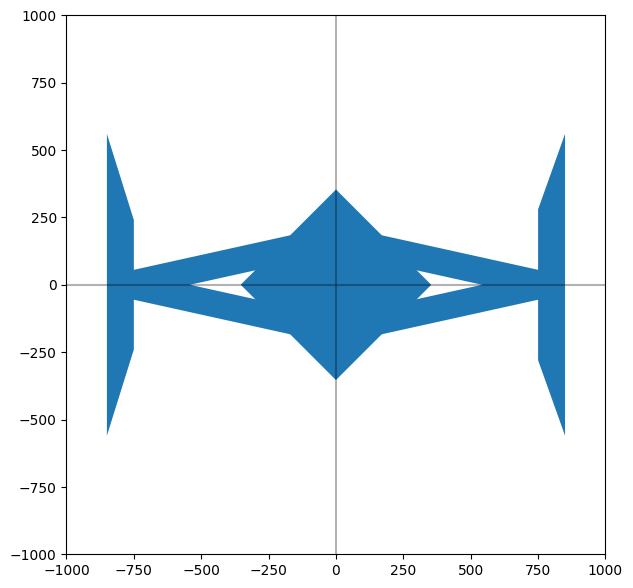

In [409]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()